# Big project: GAN, VAE and diffusion on the same digits

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-6-generators-compared.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-6-generators-compared.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/generators-compared` folder in the course files, to check your work.
- **Data**: MNIST handwritten digits (Hugging Face: ylecun/mnist). Source: [https://huggingface.co/datasets/ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist) · about: [http://yann.lecun.com/exdb/mnist/](http://yann.lecun.com/exdb/mnist/) · licence: CC BY-SA 3.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `mnist_test.npz`, `mnist_train.npz`, 11.0 MB.

In [ ]:
%pip install -q torch numpy pandas pyarrow pillow matplotlib

Over this course you built three kinds of image generator, each on its own terms: a GAN on clothes, a VAE on digits, a
diffusion model on digits. Each project measured its model a little differently, so you can't yet say which one is
better, or better at what.

This project puts all three on the same footing: the same MNIST training digits, the same judge, the same four
measurements, and the same plot. Chapter 20's introduction makes a claim you can now test: diffusion models are easy to
train and match or beat GANs on quality, but generating new samples is expensive because it needs many passes through
the network. You'll check quality, variety and speed with your own models and real numbers.

## What you'll build

```mermaid
flowchart LR
    D[MNIST training digits] --> G[GAN]
    D --> V[VAE, 16-D latent]
    D --> F[diffusion model]
    G --> C[compare.py]
    V --> C
    F --> C
    T[real test digits] --> C
    C --> R[judge sure · digit variety<br/>distance to training set · speed]
```

## Set up the project

```bash
mkdir generators-compared && cd generators-compared
python -m venv .venv && source .venv/bin/activate
pip install torch numpy pandas pyarrow pillow matplotlib
git init
```

```text
generators-compared/
    .gitignore
    README.md
    compare.py
    data.py
    diffusion.pt
    diffusion.py
    gan.py
    gan_digits.pt
    judge.pt
    judge.py
    requirements.txt
    train_diffusion.py
    train_gan.py
    train_vae.py
    unet.py
    vae.py
    vae_latent16.pt
```

In [ ]:
%%writefile requirements.txt
torch
numpy
pandas
pyarrow
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


In [ ]:
%%writefile data.py
"""MNIST handwritten digits (70,000 images, 28x28) from the Hugging Face hub, as PyTorch tensors in [0, 1]."""
from pathlib import Path
import io
import numpy as np
import pandas as pd
import torch
from PIL import Image

URL = "https://huggingface.co/api/datasets/ylecun/mnist/parquet/mnist/{}/0.parquet"


def load(split):
    """split: 'train' (60,000) or 'test' (10,000). Returns images (N, 784) and labels (N,)."""
    cache = Path(f"data/mnist_{split}.npz")
    if not cache.exists():
        cache.parent.mkdir(exist_ok=True)
        table = pd.read_parquet(URL.format(split))
        X = np.stack([np.array(Image.open(io.BytesIO(img["bytes"]))) for img in table["image"]])
        np.savez_compressed(cache, X=X, y=table["label"].values)
    d = np.load(cache)
    return torch.tensor(d["X"].reshape(len(d["X"]), -1), dtype=torch.float32) / 255, torch.tensor(d["y"]).long()

Writing data.py


## Step 1: the three models

Most of this code comes straight from your earlier projects. If you still have the trained weights (`vae_latent16.pt`,
`diffusion.pt`, `judge.pt`), copy them in and skip those runs.

**The GAN.** The networks of your clothes GAN, unchanged, now trained on digits.

In [ ]:
%%writefile gan.py
"""A generator and a discriminator (Bishop, section 17.1): two networks trained against each other."""
from torch import nn

Z = 64                                           # size of the random input vector


def generator():
    """Random vector z (64 numbers) -> a 28x28 image, pixels in [-1, 1]."""
    return nn.Sequential(nn.Linear(Z, 256), nn.LeakyReLU(0.2),
                         nn.Linear(256, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.2),
                         nn.Linear(512, 784), nn.Tanh())


def discriminator():
    """Image -> one score (a logit): high means 'this looks like a real photo'."""
    return nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
                         nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
                         nn.Linear(256, 1))

Writing gan.py


In [ ]:
%%writefile train_gan.py
"""The GAN from the clothes project, trained on MNIST digits instead (same networks, same settings)."""
import torch
import torch.nn.functional as F
from data import load
from gan import generator, discriminator, Z

torch.manual_seed(0)
x, _ = load("train")
x = x * 2 - 1
G, D = generator(), discriminator()
opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
for epoch in range(1, 16):
    order = torch.randperm(len(x))
    for s in range(0, len(x) - 127, 128):
        real, fake = x[order[s:s + 128]], G(torch.randn(128, Z))
        d_loss = F.binary_cross_entropy_with_logits(D(real), torch.ones(128, 1)) + \
                 F.binary_cross_entropy_with_logits(D(fake.detach()), torch.zeros(128, 1))
        opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        g_loss = F.binary_cross_entropy_with_logits(D(fake), torch.ones(128, 1))
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
    if epoch in (1, 5, 10, 15):
        print(f"epoch {epoch:2d}: losses D {d_loss.item():.2f}, G {g_loss.item():.2f}")
torch.save(G.state_dict(), "gan_digits.pt")

Writing train_gan.py


In [ ]:
!python train_gan.py

epoch  1: losses D 1.25, G 1.16
epoch  5: losses D 1.05, G 1.05
epoch 10: losses D 1.11, G 0.83
epoch 15: losses D 1.26, G 0.70


**The VAE.** The 16-D model from module 3.

In [ ]:
%%writefile vae.py
"""A variational autoencoder (Bishop, section 19.2)."""
import torch
import torch.nn.functional as F
from torch import nn


class VAE(nn.Module):
    def __init__(self, latent=2, hidden=400):
        super().__init__()
        self.latent = latent
        self.encoder = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 2 * latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 784))

    def encode(self, x):
        """The encoder gives, for each image, a Gaussian q(z | x): a mean and a log-variance per latent dimension
        (amortized inference, section 19.2.1)."""
        mu, log_var = self.encoder(x).chunk(2, 1)
        return mu, log_var

    def decode(self, z):
        """The decoder gives, for each latent point, the probability of each pixel being 'on' (as logits)."""
        return self.decoder(z)

    def elbo(self, x):
        """Evidence lower bound per image (equation 19.14): reconstruction log-likelihood minus KL(q(z|x) || p(z))."""
        mu, log_var = self.encode(x)
        z = mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)          # reparameterization trick (19.18)
        recon = -F.binary_cross_entropy_with_logits(self.decode(z), x, reduction="none").sum(1)
        kl = 0.5 * (mu ** 2 + log_var.exp() - 1 - log_var).sum(1)         # closed form for two Gaussians
        return recon - kl, recon, kl

Writing vae.py


In [ ]:
%%writefile train_vae.py
"""Train a VAE on MNIST. Example: python train.py --latent 2"""
import argparse
import torch
from data import load
from vae import VAE

ap = argparse.ArgumentParser()
ap.add_argument("--latent", type=int, default=2)
ap.add_argument("--epochs", type=int, default=10)
args = ap.parse_args()
torch.manual_seed(0)
x, _ = load("train")
x_test, _ = load("test")
model = VAE(args.latent)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)


@torch.no_grad()
def test_scores():
    torch.manual_seed(1)
    elbo, recon, kl = model.elbo(x_test)
    return elbo.mean().item(), recon.mean().item(), kl.mean().item()


for epoch in range(1, args.epochs + 1):
    order = torch.randperm(len(x))
    for s in range(0, len(x), 128):
        loss = -model.elbo(x[order[s:s + 128]])[0].mean()
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch in (1, 2, 5, args.epochs):
        elbo, recon, kl = test_scores()
        print(f"epoch {epoch:2d}: test ELBO {elbo:7.1f} nats per image  (reconstruction {recon:7.1f}, KL {kl:5.1f})")
torch.save(model.state_dict(), f"vae_latent{args.latent}.pt")

Writing train_vae.py


In [ ]:
!python train_vae.py --latent 16

epoch  1: test ELBO  -126.0 nats per image  (reconstruction  -105.4, KL  20.6)
epoch  2: test ELBO  -115.8 nats per image  (reconstruction   -93.7, KL  22.1)
epoch  5: test ELBO  -108.9 nats per image  (reconstruction   -86.3, KL  22.6)
epoch 10: test ELBO  -106.2 nats per image  (reconstruction   -83.3, KL  22.9)


**The diffusion model** and its judge, from module 4.

In [ ]:
%%writefile unet.py
"""A small U-Net that predicts the noise in a noisy image, given the time step t and (optionally) a digit label."""
import math
import torch
from torch import nn

NULL = 10                                        # the "no label" token, for classifier-free guidance (section 20.4.2)


def time_embedding(t, dim=64):
    """Sinusoidal embedding of the step number, like the positional encoding of transformers (section 12.1.9)."""
    half = dim // 2
    freqs = torch.exp(-math.log(1000) * torch.arange(half) / half)
    angles = t[:, None].float() * freqs[None]
    return torch.cat([angles.sin(), angles.cos()], 1)


class Block(nn.Module):
    def __init__(self, c_in, c_out, emb=64):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(c_in, c_out, 3, padding=1), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm1, self.norm2 = nn.GroupNorm(8, c_out), nn.GroupNorm(8, c_out)
        self.emb = nn.Linear(emb, c_out)
        self.act = nn.SiLU()

    def forward(self, x, e):
        h = self.act(self.norm1(self.conv1(x)))
        h = h + self.emb(e)[:, :, None, None]           # tell every pixel which step (and which digit) this is
        return self.act(self.norm2(self.conv2(h)))


class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.label = nn.Embedding(11, 64)                # digits 0-9, and NULL
        self.down1, self.down2 = Block(1, c), Block(c, 2 * c)
        self.mid = Block(2 * c, 2 * c)
        self.up2, self.up1 = Block(4 * c, c), Block(2 * c, c)
        self.pool, self.upsample = nn.AvgPool2d(2), nn.Upsample(scale_factor=2)
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x, t, y):
        e = self.t_mlp(time_embedding(t)) + self.label(y)
        h1 = self.down1(x, e)                            # 28 x 28
        h2 = self.down2(self.pool(h1), e)                # 14 x 14
        m = self.mid(self.pool(h2), e)                   # 7 x 7
        u2 = self.up2(torch.cat([self.upsample(m), h2], 1), e)     # skip connections: the "U"
        u1 = self.up1(torch.cat([self.upsample(u2), h1], 1), e)
        return self.out(u1)

Writing unet.py


In [ ]:
%%writefile diffusion.py
"""Denoising diffusion (Bishop, chapter 20), in the book's notation: alpha_t is the PRODUCT of (1 - beta) up to t."""
import torch
from unet import NULL

T = 500
beta = torch.linspace(1e-4, 0.04, T)                     # the noise schedule beta_1 ... beta_T
alpha = torch.cumprod(1 - beta, 0)                       # alpha_t = prod (1 - beta_tau)  (Algorithm 20.1)


def noisy(x, t, eps):
    """z_t = sqrt(alpha_t) x + sqrt(1 - alpha_t) eps: jump straight to step t (the diffusion kernel, section 20.1.1)."""
    a = alpha[t][:, None, None, None]
    return a.sqrt() * x + (1 - a).sqrt() * eps


def loss(model, x, y, p_null=0.15):
    """Algorithm 20.1: noise an image to a random step, and train the network to predict the noise (section 20.2.4).
    With probability p_null the label is replaced by NULL, so one network learns both p(x | digit) and p(x)."""
    t = torch.randint(0, T, (len(x),))
    eps = torch.randn_like(x)
    y = torch.where(torch.rand(len(y)) < p_null, torch.full_like(y, NULL), y)
    return ((model(noisy(x, t, eps), t, y) - eps) ** 2).mean()


@torch.no_grad()
def sample(model, y, guidance=1.0, generator=None):
    """Algorithm 20.2, with classifier-free guidance (equation 20.60):
    predicted noise = guidance * eps(z, t, digit) + (1 - guidance) * eps(z, t, NULL)."""
    n = len(y)
    z = torch.randn(n, 1, 28, 28, generator=generator)
    null = torch.full_like(y, NULL)
    for t in range(T - 1, -1, -1):
        tt = torch.full((n,), t)
        if guidance == 0:
            eps = model(z, tt, null)
        elif guidance == 1:
            eps = model(z, tt, y)
        else:
            both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([y, null]))
            eps = guidance * both[:n] + (1 - guidance) * both[n:]
        mean = (z - beta[t] / (1 - alpha[t]).sqrt() * eps) / (1 - beta[t]).sqrt()
        z = mean + beta[t].sqrt() * torch.randn(z.shape, generator=generator) if t > 0 else mean
    return z.clamp(-1, 1)

Writing diffusion.py


In [ ]:
%%writefile train_diffusion.py
"""Train the diffusion model on MNIST: images scaled to [-1, 1], labels dropped 15% of the time."""
import argparse
import torch
from data import load
from unet import UNet
from diffusion import loss

ap = argparse.ArgumentParser()
ap.add_argument("--steps", type=int, default=6000)
args = ap.parse_args()
torch.manual_seed(0)
x, y = load("train")
x = x.reshape(-1, 1, 28, 28) * 2 - 1
model = UNet()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
opt = torch.optim.AdamW(model.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=args.steps)
running = 0.0
for step in range(1, args.steps + 1):
    idx = torch.randint(0, len(x), (128,))
    l = loss(model, x[idx], y[idx])
    opt.zero_grad(); l.backward(); opt.step(); sched.step()
    running = 0.98 * running + 0.02 * l.item() if step > 1 else l.item()
    if step % 1000 == 0 or step == 1:
        print(f"step {step:5d}: noise-prediction loss {running:.4f}")
torch.save(model.state_dict(), "diffusion.pt")

Writing train_diffusion.py


In [ ]:
!python train_diffusion.py

237,217 parameters
step     1: noise-prediction loss 1.2349
step  1000: noise-prediction loss 0.0351
step  2000: noise-prediction loss 0.0291
step  3000: noise-prediction loss 0.0269
step  4000: noise-prediction loss 0.0249
step  5000: noise-prediction loss 0.0238
step  6000: noise-prediction loss 0.0238


In [ ]:
%%writefile judge.py
"""A separate digit classifier, the 'judge': it scores how recognizable generated digits are, and which digit each is."""
import torch
import torch.nn.functional as F
from torch import nn
from data import load


def judge_net():
    return nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 49, 10))


if __name__ == "__main__":
    torch.manual_seed(0)
    x, y = load("train"); xt, yt = load("test")
    net = judge_net(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for epoch in range(2):
        order = torch.randperm(len(x))
        for s in range(0, len(x), 128):
            i = order[s:s + 128]
            l = F.cross_entropy(net(x[i] * 2 - 1), y[i]); opt.zero_grad(); l.backward(); opt.step()
    with torch.no_grad():
        acc = (net(xt * 2 - 1).argmax(1) == yt).float().mean().item()
    print(f"judge accuracy on real test digits: {acc:.3f}")
    torch.save(net.state_dict(), "judge.pt")

Writing judge.py


In [ ]:
!python judge.py

judge accuracy on real test digits: 0.987


## Step 2: one judge, four measurements

`compare.py` draws 200 digits from each model, without asking for any particular digit, and measures them the same way.
Real test digits, which none of the models saw, go through the same checks as a reference row.

- **judge sure**: the share of images the judge classifies with at least 90% confidence. A rough measure of quality.
- **digit variety**: the "effective number of digits" among the judge's answers, `exp(entropy)`. 10 means all ten
  digits equally often; a model that only draws 1s scores 1. This catches mode collapse.
- **distance to nearest training digit**: the median pixel distance from each image to its closest training digit. Too
  small would mean the model copies its training data; real test digits show what a normal distance looks like.
- **ms per image**: how long one image takes on this CPU.

In [ ]:
%%writefile compare.py
"""Three generators, one judge: quality, variety, novelty and speed, measured the same way for each."""
import math
import time
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load
from gan import generator, Z
from vae import VAE
from unet import UNet, NULL
from diffusion import sample
from judge import judge_net

N = 200
x_train, _ = load("train")
judge = judge_net(); judge.load_state_dict(torch.load("judge.pt")); judge.eval()
G = generator(); G.load_state_dict(torch.load("gan_digits.pt")); G.eval()
vae = VAE(16); vae.load_state_dict(torch.load("vae_latent16.pt")); vae.eval()
unet = UNet(); unet.load_state_dict(torch.load("diffusion.pt")); unet.eval()
g = torch.Generator().manual_seed(0)
makers = {
    "GAN": lambda: G(torch.randn(N, Z, generator=g)),                                         # pixels in [-1, 1]
    "VAE (16-D)": lambda: torch.sigmoid(vae.decode(torch.randn(N, 16, generator=g))) * 2 - 1,
    "diffusion": lambda: sample(unet, torch.full((N,), NULL), guidance=0, generator=g).reshape(N, -1),
}
real = load("test")[0][:N] * 2 - 1                 # real digits the generators never saw
rows, grids = [], {}
print(f"{'model':12s} {'judge sure':>10s} {'digit variety':>14s} {'distance to nearest training digit':>35s} {'ms per image':>12s}")
for name, make in [("real (test)", lambda: real)] + list(makers.items()):
    start = time.time()
    with torch.no_grad():
        imgs = make()
    ms = 1000 * (time.time() - start) / N
    with torch.no_grad():
        p = torch.softmax(judge(imgs), 1)
    sure = (p.max(1).values > 0.9).float().mean().item()
    counts = torch.bincount(p.argmax(1), minlength=10).float()
    q = counts / counts.sum()
    variety = math.exp(-(q[q > 0] * q[q > 0].log()).sum().item())          # "effective number of digits", max 10
    nearest = torch.cdist(imgs, x_train[:20000] * 2 - 1).min(1).values.median().item()
    print(f"{name:12s} {sure:10.0%} {variety:14.1f} {nearest:35.1f} {ms if name != 'real (test)' else 0:12.1f}")
    grids[name] = imgs[:16]

Path("outputs").mkdir(exist_ok=True)
fig, axes = plt.subplots(4, 16, figsize=(12, 3.4))
for r, (name, imgs) in enumerate(grids.items()):
    for c in range(16):
        axes[r, c].imshow(imgs[c].reshape(28, 28), cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(name, fontsize=8, loc="left")
fig.tight_layout(); fig.savefig("outputs/side_by_side.png", dpi=90)
print("saved outputs/side_by_side.png")

Writing compare.py


In [ ]:
!python compare.py

model        judge sure  digit variety  distance to nearest training digit ms per image
real (test)         96%            9.7                                 9.1          0.0
GAN                 56%            9.1                                10.8          0.0
VAE (16-D)          29%            9.0                                 9.7          0.0
diffusion           54%            9.4                                11.4       1100.0
saved outputs/side_by_side.png


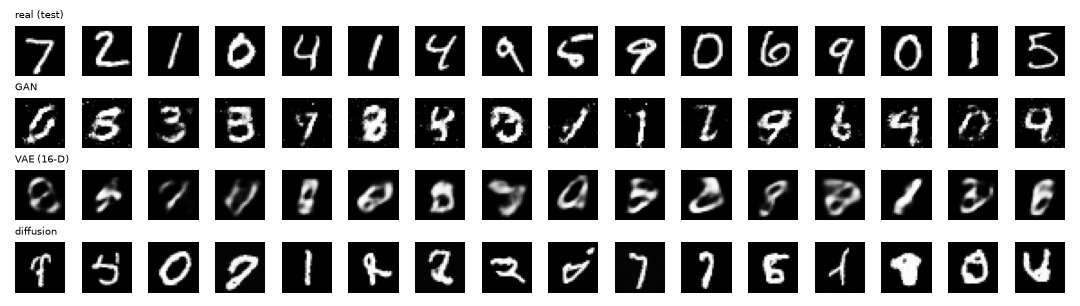

In [ ]:
from IPython.display import Image
Image('outputs/side_by_side.png')

Read each column, with the real test digits as the reference:

- **Quality (judge sure).** Real digits score 96%. The GAN (56%) and the diffusion model (54%) are close, and the VAE
  trails at 29%. The picture shows three different failures: the GAN's digits are speckled with noise, the VAE's are
  blurry averages, and the diffusion model's strokes are clean but some shapes are odd.
- **Variety.** All three draw every digit: 9.0 to 9.4 effective digits, against 9.7 for real ones. None of them has
  collapsed onto a few digits.
- **Novelty.** No model copies its training data: every median distance is above the 9.1 of real test digits. The
  VAE's 9.7 is the lowest because blurry averages sit close to many training digits at once, not because it copies.
- **Speed.** This is where diffusion pays: 1.1 seconds per image, because each image takes 500 passes through the U-Net.
  The GAN and the VAE need one pass each, well under 0.1 ms per image here, which the table rounds to 0.0.

Chapter 20's claim holds on your own models: diffusion matches the GAN on quality without any adversarial game to
balance, and pays for it at sampling time, more than ten thousand times slower. A small diffusion model trained for half an hour
doesn't beat the GAN here; with a bigger network and longer training, diffusion is what modern image generators use.

## Step 3: write the README and publish

This README is the one recruiters will read first, so put the results table at the top.

In [ ]:
%%writefile README.md
# GAN vs VAE vs diffusion on the same digits

Three generative models written in PyTorch and trained on the same MNIST digits, then measured the same way: one CNN
judge, 200 samples each, four measurements. Real test digits, which no model saw, are the reference row.

![side by side](outputs/side_by_side.png)

## Results (200 samples per model)

| model | judge at least 90% sure | digit variety (max 10) | median distance to nearest training digit | ms per image |
|---|---|---|---|---|
| real test digits | 96% | 9.7 | 9.1 | - |
| GAN (MLP) | **56%** | 9.1 | 10.8 | under 0.1 |
| VAE (16-D latent) | 29% | 9.0 | 9.7 | under 0.1 |
| diffusion (DDPM, 500 steps) | 54% | **9.4** | 11.4 | 1,100 |

- **Quality:** the GAN and diffusion are close; the VAE's samples are blurry.
- **Variety:** all three draw every digit, so no mode collapse.
- **Novelty:** no model copies its training data (every distance is above that of real test digits).
- **Speed:** diffusion is more than ten thousand times slower to sample, because each image needs 500 network passes.

## Run it

```bash
pip install -r requirements.txt
python train_gan.py
python train_vae.py --latent 16
python train_diffusion.py
python judge.py
python compare.py   # saves outputs/side_by_side.png
```

## What I learned

- Each model fails in its own way: GAN samples are noisy, VAE samples are blurry, diffusion samples are clean but
  sometimes oddly shaped.
- One shared judge and shared measurements make models comparable; each project's own metric didn't.
- Diffusion trades sampling speed for easy, stable training with a single loss.

Based on chapters 17 to 20 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "GAN vs VAE vs diffusion on MNIST: quality, variety, novelty, speed"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/generators-compared.git
git push -u origin main
```

## Make it yours

- **Add the flow.** Train a Real NVP on the digits (your module 2 code, with more layers) and add it as a fourth row.
  Unlike the others, it can also give each test digit an exact log-likelihood.
- **A fairer GAN.** Swap the MLP GAN for a small convolutional one (DCGAN). How much of the gap closes?
- **Faster diffusion.** Sample with 50 steps instead of 500 (every 10th step). How do speed and quality trade?
- **FID.** Replace "judge sure" with a Fréchet distance between the judge's hidden features for real and generated
  digits, the standard measure in papers.

## On your CV

> **Generative models compared** (PyTorch): trained a GAN, a VAE and a DDPM on MNIST and compared them with one CNN
> judge: confident share (GAN 56%, diffusion 54%, VAE 29%, real 96%), effective class variety (9.0 to 9.4 of 10),
> novelty (median distance to the nearest training digit) and speed (diffusion 1.1 s per image, 500 steps).
> github.com/YOUR-USERNAME/generators-compared

## Check yourself

- [ ] You can name one strength and one weakness of each of the three models, backed by your own numbers.
- [ ] You can explain why the distance to the nearest training digit is a useful sanity check.
- [ ] You can explain why diffusion is slow to sample but easy to train.